In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 92.4 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.8.93
    Uninstalling nvidia-nvjitlink-cu12-12.8.93:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.8.93
  Attempting uninstall: nvidia-curand-cu12
    Found existing installation: nvidia-curand-cu12 10.3.9.90
    Uninstalling nvidia-curand-cu12-10.3.

In [2]:
import os
from glob import glob
from tqdm.notebook import tqdm
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from shapely.geometry import Polygon
import pandas as pd
import random
import torch
import cv2

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
# Set the seed value
SEED = 42  

# Python’s built-in random module
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Ensure deterministic behavior in PyTorch
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Set PYTHONHASHSEED to ensure consistent behavior in hash-based operations
os.environ["PYTHONHASHSEED"] = str(SEED)

In [4]:
# Paths
val_images_dir = '/kaggle/input/rasoul-b-e-s-obb/dataset/images/val'
val_labels_dir = '/kaggle/input/rasoul-b-e-s-obb/dataset/labels/val'

# Automatically collect all .pt weights from the directory
weights_dir = '/kaggle/input/rasoul-b-e-s-obb-detection-weights/BinaryDetectionWeights'
model_paths = [os.path.join(weights_dir, f) for f in os.listdir(weights_dir) if f.endswith('.pt')]

# Saving the outputs
os.makedirs("/kaggle/working/myplots/ConfMats", exist_ok=True)

In [5]:
def load_yolo_labels(path, with_conf=False):
    labels = {}
    for label_file in glob(f"{path}/*.txt"):
        with open(label_file, "r") as f:
            lines = f.read().strip().split("\n")
            boxes = []
            for line in lines:
                if not line.strip():
                    continue
                parts = list(map(float, line.strip().split()))
                if with_conf and len(parts) == 10:
                    conf = parts[-1]
                    box = parts[1:9]
                    boxes.append((conf, box))
                elif not with_conf and len(parts) == 9:
                    box = parts[1:9]
                    boxes.append(box)
                else:
                    print(f"⚠️ Skipping malformed line: {line} in {label_file}")
            labels[os.path.basename(label_file)] = boxes
    return labels

In [6]:
def normalize_to_sorted_polygon(box, image_shape=(640, 640)):
    pts = np.array([(box[i]*image_shape[1], box[i+1]*image_shape[0]) for i in range(0, 8, 2)], dtype=np.float32)
    rect = cv2.minAreaRect(pts)
    box_pts = cv2.boxPoints(rect)  # always returns 4 corners in consistent order
    return Polygon(box_pts)

In [7]:
def compute_iou(box1, box2, image_shape=(640, 640)):
    poly1 = normalize_to_sorted_polygon(box1, image_shape)
    poly2 = normalize_to_sorted_polygon(box2, image_shape)
    if not poly1.is_valid or not poly2.is_valid:
        return 0.0
    inter = poly1.intersection(poly2).area
    union = poly1.union(poly2).area
    return inter / union if union > 0 else 0.0

In [8]:
# Iterate through models and compute optimal threshold
output_results = []
pbar = tqdm(total=len(model_paths), desc="Processing models")

for model_path in model_paths:
    model_name = os.path.basename(model_path).replace('.pt', '')

    # Prediction directory — match YOLOv8's output structure
    predict_dir = f"/kaggle/working/runs/obb/yolo_validation_predictions_{model_name}_test/labels"

    # If predictions don't exist, run inference
    if not os.path.exists(predict_dir):
        model = YOLO(model_path)
        model.predict(
            source=val_images_dir,
            save_txt=True,
            save_conf=True,
            conf=0.001,
            name=f"yolo_validation_predictions_{model_name}_test",
            verbose=False,
        )

    # Load predictions and ground truth labels
    preds = load_yolo_labels(predict_dir, with_conf=True)
    gts = load_yolo_labels(val_labels_dir, with_conf=False)

    # Threshold range for evaluation
    thresholds = np.arange(0.05, 0.96, 0.05)
    best_f1, best_threshold = 0, 0
    best_precision, best_recall = 0, 0

    # Iterate over thresholds to compute metrics
    for t in thresholds:
        TP = FP = FN = 0

        for filename in gts.keys():
            gt_boxes = gts.get(filename, [])
            pred_boxes = [b[1] for b in preds.get(filename, []) if b[0] >= t]

            matched = set()
            for gt in gt_boxes:
                found_match = False
                for i, pred in enumerate(pred_boxes):
                    if i in matched:
                        continue
                    if compute_iou(gt, pred, image_shape=(640, 640)) >= 0.5:
                        TP += 1
                        matched.add(i)
                        found_match = True
                        break
                if not found_match:
                    FN += 1
            FP += len(pred_boxes) - len(matched)
            
        # Calculate precision, recall, and F1 score
        precision = TP / (TP + FP + 1e-6)
        recall = TP / (TP + FN + 1e-6)
        f1 = 2 * precision * recall / (precision + recall + 1e-6)

        # Keep track of the best F1 score and corresponding metrics
        if f1 > best_f1:
            best_f1 = f1
            best_threshold = t
            best_precision = precision
            best_recall = recall
        
    ious = np.arange(0.5, 1.0, 0.05)
    aps = []

    for iou_thresh in ious:
        all_scores = []
        all_tp_flags = []
        num_gt_boxes = 0

        for filename in gts.keys():
            gt_boxes = gts.get(filename, [])
            preds_info = preds.get(filename, [])
            pred_boxes = [b[1] for b in preds_info if b[0] >= best_threshold]
            pred_scores = [b[0] for b in preds_info if b[0] >= best_threshold]

            matched = set()
            num_gt_boxes += len(gt_boxes)
            tp_flags = [0] * len(pred_boxes)   #  Each pred box is initially assumed FP

            for gt in gt_boxes:
                best_iou = 0
                best_idx = -1
                for i, pred in enumerate(pred_boxes):
                    if i in matched:
                        continue
                    iou = compute_iou(gt, pred, image_shape=(640, 640))
                    if iou >= iou_thresh and iou > best_iou:
                        best_iou = iou
                        best_idx = i
                if best_idx != -1:
                    tp_flags[best_idx] = 1
                    matched.add(best_idx)

            all_scores.extend(pred_scores)
            all_tp_flags.extend(tp_flags)

        if all_scores:
            sorted_indices = np.argsort(-np.array(all_scores))
            tp_flags_sorted = np.array(all_tp_flags)[sorted_indices]

            tp_cum = np.cumsum(tp_flags_sorted)
            fp_cum = np.cumsum(1 - tp_flags_sorted)

            precision_curve = tp_cum / (tp_cum + fp_cum + 1e-6)
            recall_curve = tp_cum / (num_gt_boxes + 1e-6)   # Denominator = total GT boxes

            ap = 0.0
            for r in np.linspace(0, 1, 11):
                prec_at_r = precision_curve[recall_curve >= r].max() if np.any(recall_curve >= r) else 0
                ap += prec_at_r
            ap /= 11.0
        else:
            ap = 0.0

        aps.append(ap)

    # Final results
    map50 = aps[0]
    map5095 = np.mean(aps)

    # Append results for the current model
    output_results.append({
        'model': model_name,
        'best_threshold': best_threshold,
        'f1': best_f1,
        'precision': best_precision,
        'recall': best_recall,
        'mAP@0.5': map50,
        'mAP@0.5:0.95': map5095
    })
    pbar.update(1)
pbar.close()

Processing models:   0%|          | 0/6 [00:00<?, ?it/s]

WARNING ⚠️ 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to runs/obb/yolo_validation_predictions_yolo11s-obb_test
270 labels saved to runs/obb/yolo_validation_predictions_yolo11s-obb_test/labels
WARNING ⚠️ 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator o

In [9]:
models = [
    "yolov8n-obb", "yolov8s-obb", "yolov8m-obb",
    "yolo11n-obb", "yolo11s-obb", "yolo11m-obb"
]

Best Model Performance Metrics
         model  best_threshold        f1  precision    recall   mAP@0.5  \
0  yolov8n-obb            0.45  0.554002   0.767606  0.433400  0.423297   
1  yolo11n-obb            0.20  0.539801   0.720930  0.431412  0.426009   
2  yolo11m-obb            0.45  0.531486   0.725086  0.419483  0.400362   
3  yolov8s-obb            0.15  0.525925   0.693811  0.423459  0.419322   
4  yolo11s-obb            0.55  0.513548   0.731618  0.395626  0.340877   
5  yolov8m-obb            0.25  0.509316   0.678808  0.407555  0.401168   

   mAP@0.5:0.95  
0      0.181154  
1      0.205328  
2      0.163190  
3      0.171344  
4      0.158917  
5      0.167783  


/tmp/ipykernel_19/377313009.py:15: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
/tmp/ipykernel_19/377313009.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
/tmp/ipykernel_19/377313009.py:25: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[2].set_xticklabels(df_ordered['model'], rotation=45, ha='right')


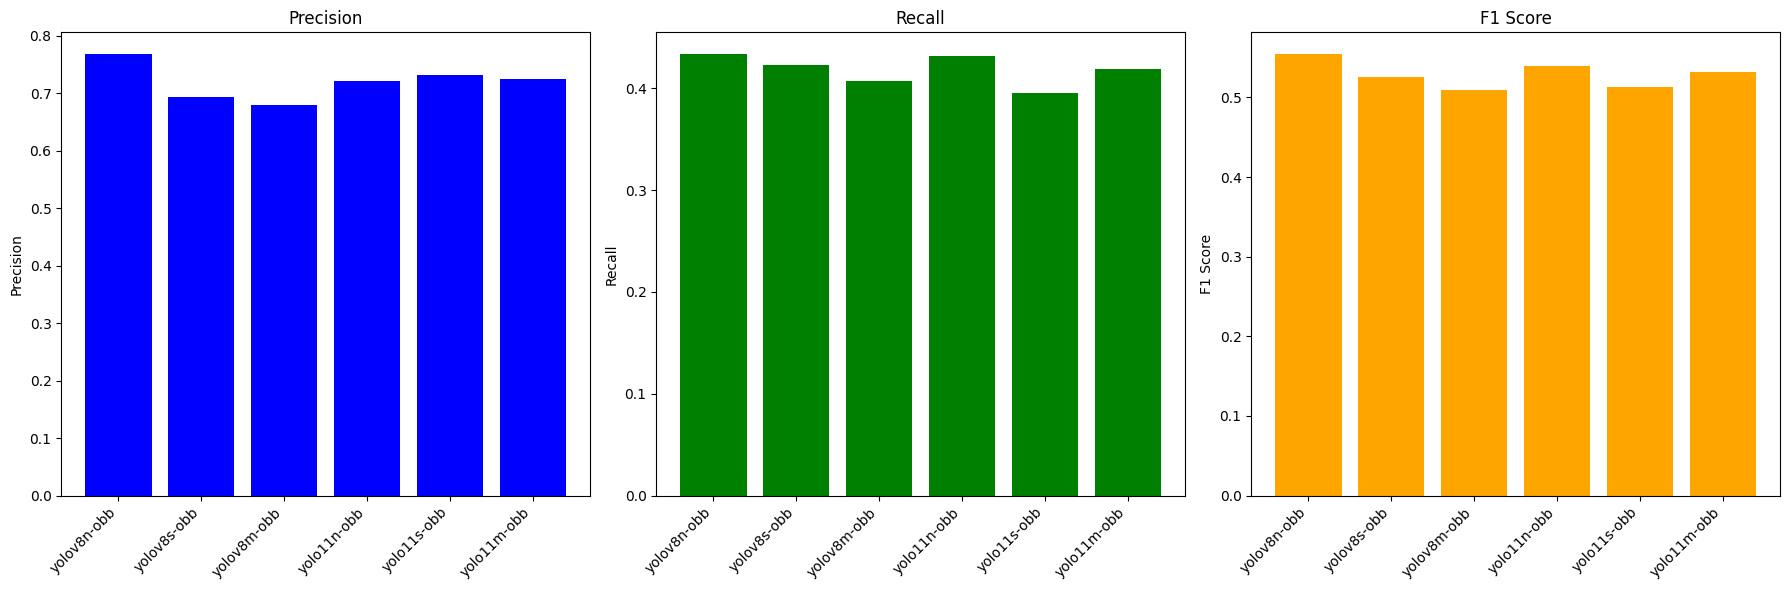

/tmp/ipykernel_19/377313009.py:37: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
/tmp/ipykernel_19/377313009.py:43: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')


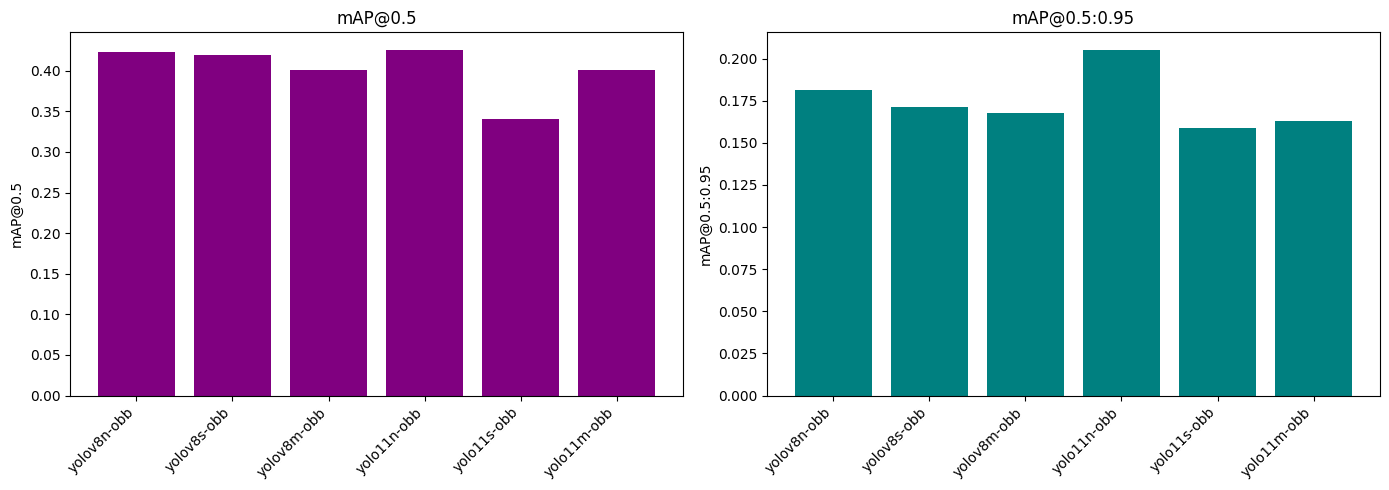

/tmp/ipykernel_19/377313009.py:57: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(df_precision_sorted['model'], rotation=45, ha='right')
/tmp/ipykernel_19/377313009.py:64: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[1].set_xticklabels(df_recall_sorted['model'], rotation=45, ha='right')
/tmp/ipykernel_19/377313009.py:71: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[2].set_xticklabels(df_f1_sorted['model'], rotation=45, ha='right')


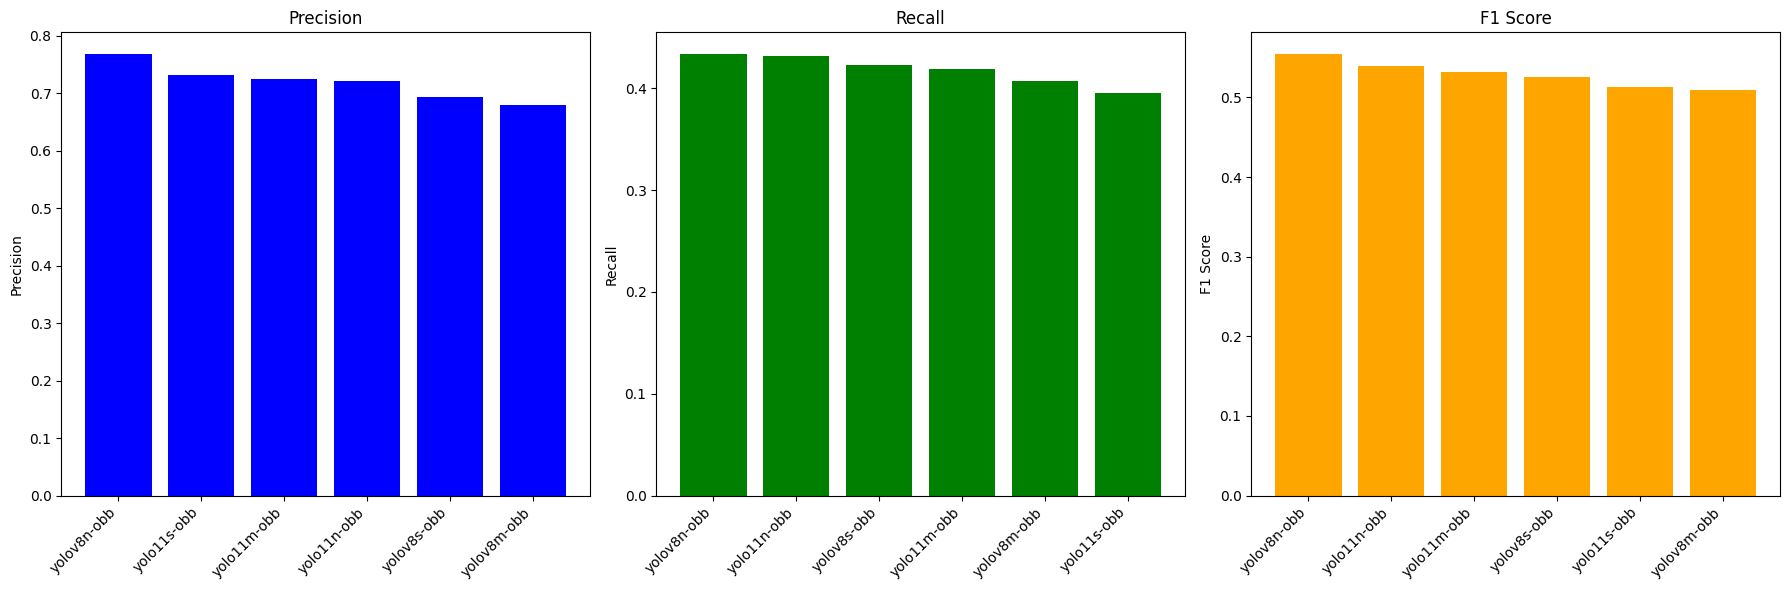

/tmp/ipykernel_19/377313009.py:84: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[0].set_xticklabels(df_map50_sorted['model'], rotation=45, ha='right')
/tmp/ipykernel_19/377313009.py:91: UserWarning: FixedFormatter should only be used together with FixedLocator
  axes[1].set_xticklabels(df_map5095_sorted['model'], rotation=45, ha='right')


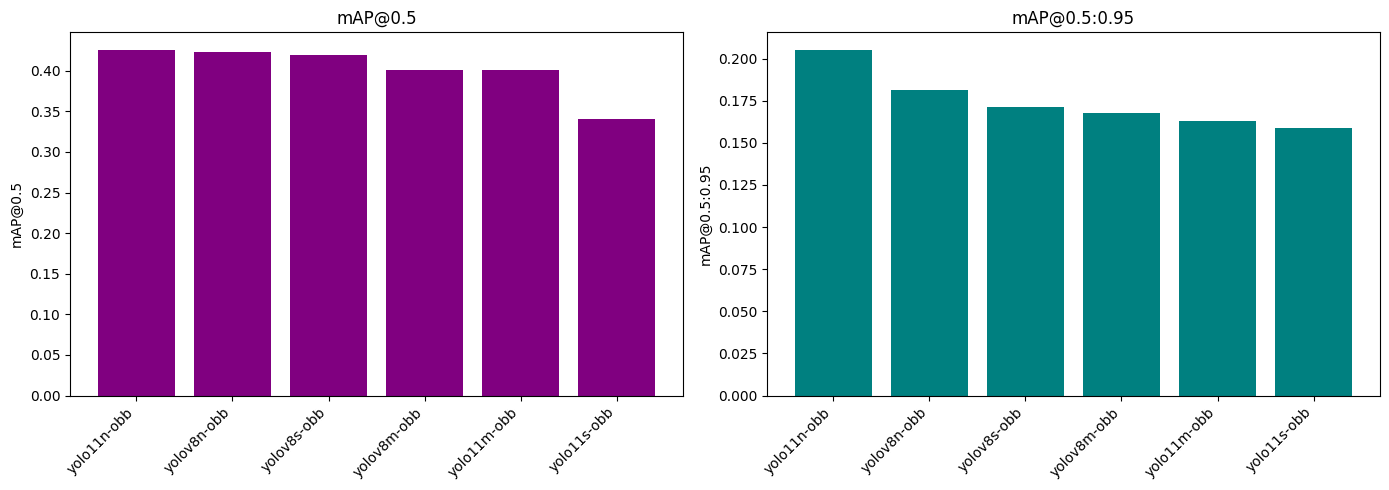

In [10]:
# Create a DataFrame to summarize the results
df = pd.DataFrame(output_results)
df = df.sort_values(by='f1', ascending=False).reset_index(drop=True)
df_ordered = df.set_index('model').reindex(models).reset_index()

# Display the results as a table
print("Best Model Performance Metrics")
print(df)

# ---------- SET 1: PLOTS SORTED BY MODELS ---------- #

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].bar(df_ordered['model'], df_ordered['precision'], color='blue')
axes[0].set_title('Precision')
axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
axes[0].set_ylabel('Precision')

axes[1].bar(df_ordered['model'], df_ordered['recall'], color='green')
axes[1].set_title('Recall')
axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
axes[1].set_ylabel('Recall')

axes[2].bar(df_ordered['model'], df_ordered['f1'], color='orange')
axes[2].set_title('F1 Score')
axes[2].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
axes[2].set_ylabel('F1 Score')

plt.tight_layout()
plt.savefig(f"/kaggle/working/myplots/MetricPlots-msorted.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# mAP@0.5
axes[0].bar(df_ordered['model'], df_ordered['mAP@0.5'], color='purple')
axes[0].set_title('mAP@0.5')
axes[0].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
axes[0].set_ylabel('mAP@0.5')

# mAP@0.5:0.95
axes[1].bar(df_ordered['model'], df_ordered['mAP@0.5:0.95'], color='teal')
axes[1].set_title('mAP@0.5:0.95')
axes[1].set_xticklabels(df_ordered['model'], rotation=45, ha='right')
axes[1].set_ylabel('mAP@0.5:0.95')

plt.tight_layout()
plt.savefig("/kaggle/working/myplots/mAPPlots-msorted.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- SET 2: PLOTS SORTED BY METRIC VALUE ---------- #
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Precision (sorted)
df_precision_sorted = df.sort_values(by='precision', ascending=False)
axes[0].bar(df_precision_sorted['model'], df_precision_sorted['precision'], color='blue')
axes[0].set_title('Precision')
axes[0].set_xticklabels(df_precision_sorted['model'], rotation=45, ha='right')
axes[0].set_ylabel('Precision')

# Recall (sorted)
df_recall_sorted = df.sort_values(by='recall', ascending=False)
axes[1].bar(df_recall_sorted['model'], df_recall_sorted['recall'], color='green')
axes[1].set_title('Recall')
axes[1].set_xticklabels(df_recall_sorted['model'], rotation=45, ha='right')
axes[1].set_ylabel('Recall')

# F1 Score (sorted)
df_f1_sorted = df.sort_values(by='f1', ascending=False)
axes[2].bar(df_f1_sorted['model'], df_f1_sorted['f1'], color='orange')
axes[2].set_title('F1 Score')
axes[2].set_xticklabels(df_f1_sorted['model'], rotation=45, ha='right')
axes[2].set_ylabel('F1 Score')

plt.tight_layout()
plt.savefig(f"/kaggle/working/myplots/MetricPlots-vsorted.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# mAP@0.5 (sorted)
df_map50_sorted = df.sort_values(by='mAP@0.5', ascending=False)
axes[0].bar(df_map50_sorted['model'], df_map50_sorted['mAP@0.5'], color='purple')
axes[0].set_title('mAP@0.5')
axes[0].set_xticklabels(df_map50_sorted['model'], rotation=45, ha='right')
axes[0].set_ylabel('mAP@0.5')

# mAP@0.5:0.95 (sorted)
df_map5095_sorted = df.sort_values(by='mAP@0.5:0.95', ascending=False)
axes[1].bar(df_map5095_sorted['model'], df_map5095_sorted['mAP@0.5:0.95'], color='teal')
axes[1].set_title('mAP@0.5:0.95')
axes[1].set_xticklabels(df_map5095_sorted['model'], rotation=45, ha='right')
axes[1].set_ylabel('mAP@0.5:0.95')

plt.tight_layout()
plt.savefig("/kaggle/working/myplots/mAPPlots-vsorted.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
df.to_csv('/kaggle/working/myplots/model_performance_summary.csv', index=False)

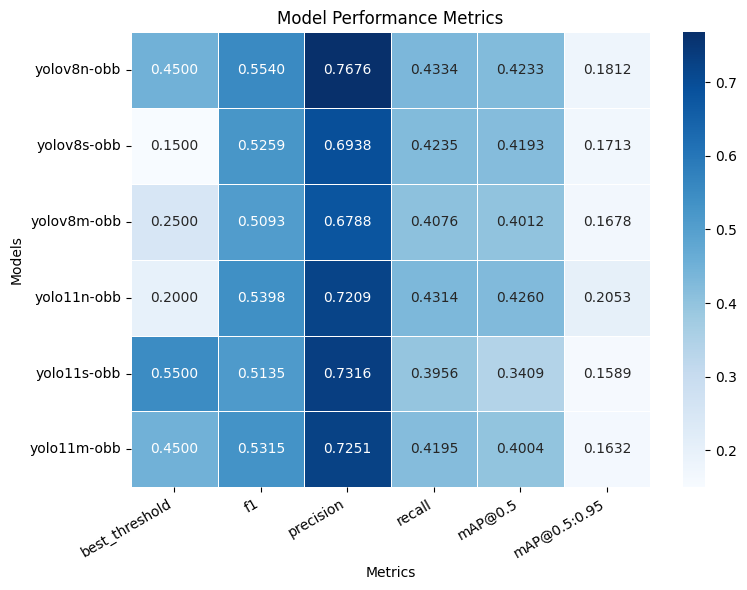

In [12]:
# Format and reindex df
df_rounded = df.copy()
df_rounded[["precision", "recall", "f1", "best_threshold", "mAP@0.5", "mAP@0.5:0.95"]] = df_rounded[["precision", "recall", "f1", "best_threshold", "mAP@0.5", "mAP@0.5:0.95"]].round(4)
df_rounded.set_index("model", inplace=True)
df_ordered = df_rounded.loc[models]  # Reorder rows

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_ordered, annot=True, fmt=".4f", cmap="Blues", linewidths=0.5, cbar=True)
plt.title("Model Performance Metrics")
plt.xlabel("Metrics")
plt.ylabel("Models")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"/kaggle/working/myplots/MetricsTable.png", dpi=300, bbox_inches="tight")
plt.show()

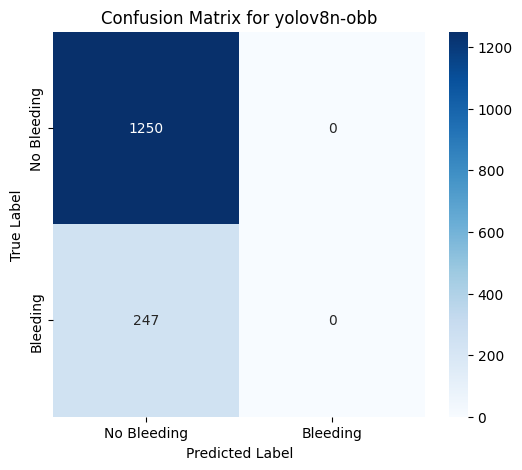

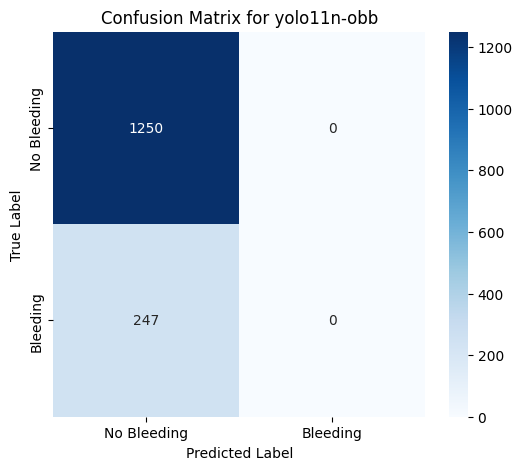

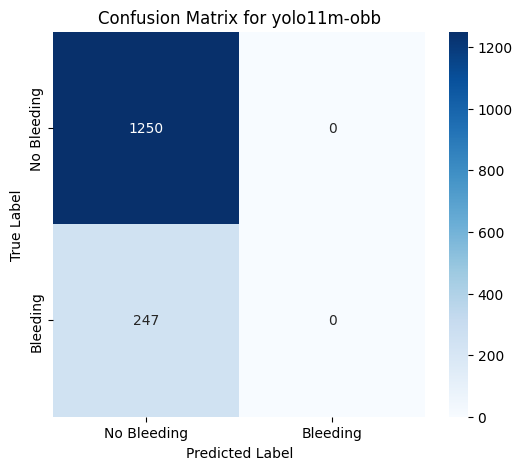

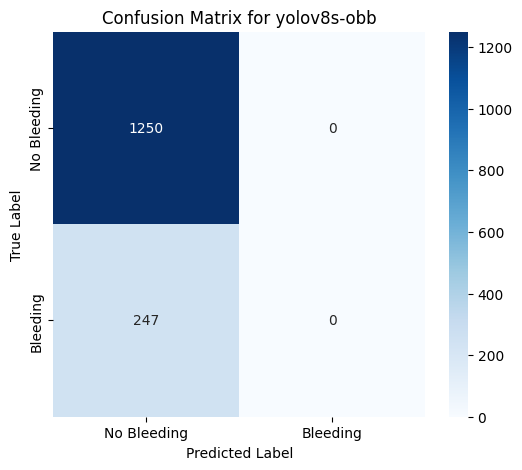

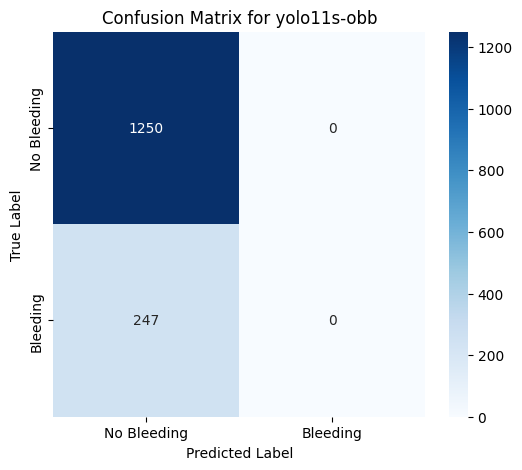

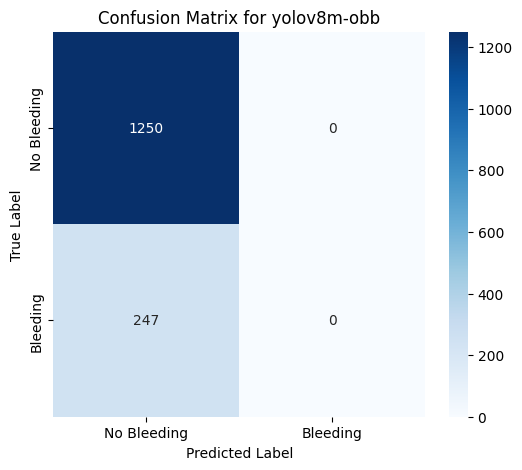

In [13]:
# The confusion matrices for each model
for model_name in df['model']:
    # Get the best threshold for each model
    best_threshold = df[df['model'] == model_name]['best_threshold'].values[0]
    
    preds = load_yolo_labels(f"/kaggle/working/runs/detect/yolo_validation_predictions_{model_name}_test/labels", with_conf=True)
    gts = load_yolo_labels(val_labels_dir, with_conf=False)

    y_true = []
    y_pred = []

    for filename in gts.keys():
        gt_boxes = gts.get(filename, [])
        pred_boxes = [b[1] for b in preds.get(filename, []) if b[0] >= best_threshold]

        # Convert ground truth and prediction to binary labels
        y_true.append(1 if len(gt_boxes) > 0 else 0)
        y_pred.append(1 if len(pred_boxes) > 0 else 0)

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Bleeding', 'Bleeding'], yticklabels=['No Bleeding', 'Bleeding'])
    plt.title(f"Confusion Matrix for {model_name}")
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.savefig(f"/kaggle/working/myplots/ConfMats/{model_name}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [14]:
!zip -r /kaggle/working/C-thresholdplots.zip /kaggle/working/myplots

  adding: kaggle/working/myplots/ (stored 0%)
  adding: kaggle/working/myplots/mAPPlots-vsorted.png (deflated 26%)
  adding: kaggle/working/myplots/mAPPlots-msorted.png (deflated 25%)
  adding: kaggle/working/myplots/ConfMats/ (stored 0%)
  adding: kaggle/working/myplots/ConfMats/yolov8n-obb.png (deflated 18%)
  adding: kaggle/working/myplots/ConfMats/yolov8s-obb.png (deflated 17%)
  adding: kaggle/working/myplots/ConfMats/yolo11m-obb.png (deflated 18%)
  adding: kaggle/working/myplots/ConfMats/yolov8m-obb.png (deflated 17%)
  adding: kaggle/working/myplots/ConfMats/yolo11s-obb.png (deflated 18%)
  adding: kaggle/working/myplots/ConfMats/yolo11n-obb.png (deflated 18%)
  adding: kaggle/working/myplots/MetricPlots-msorted.png (deflated 31%)
  adding: kaggle/working/myplots/MetricsTable.png (deflated 10%)
  adding: kaggle/working/myplots/MetricPlots-vsorted.png (deflated 31%)
  adding: kaggle/working/myplots/model_performance_summary.csv (deflated 47%)
